<a href="https://colab.research.google.com/github/L1S23BSCS0119/Loan-Prediction/blob/main/Loan_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Prediction: Preparing Data for Machine Learning


## Step 0 — Choose the dataset
I chose the **Loan Prediction Problem Dataset** because its labeled training file has 614 rows and 13 columns, including numeric values, categories, and existing missing values. It meets the assignment requirements without adding artificial missing data.

- [Kaggle source](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset)
- [CSV mirror used by this notebook](https://github.com/shrikant-temburwar/Loan-Prediction-Dataset/blob/master/train.csv)

The loader first looks for `loan_prediction.csv` beside the notebook. Otherwise, it downloads the CSV and saves that local copy.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('loan_prediction.csv')
DATA_URL = 'https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv'
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print('Loaded the local dataset:', DATA_PATH)
else:
    try:
        df = pd.read_csv(DATA_URL)
    except Exception as exc:
        raise RuntimeError(
            'Download the labeled training CSV from the dataset source, '
            'rename it loan_prediction.csv, place it beside this notebook, and rerun.'
        ) from exc
    df.to_csv(DATA_PATH, index=False)
    print('Downloaded and saved:', DATA_PATH)

expected_columns = {
    'Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
    'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
    'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'
}
assert set(df.columns) == expected_columns, 'Check that you loaded the correct labeled CSV.'
assert len(df) >= 500, 'The assignment requires at least 500 rows.'
assert df.isna().any().any(), 'The raw dataset should contain missing values.'
raw_df = df.copy()

Downloaded and saved: loan_prediction.csv


## Step 1 — Load and explore (EDA)
I check the dimensions, column types, sample rows, and summary statistics to understand the data. I then look at the approval counts, approval by property area, the income distribution, and correlations among numeric columns. These charts describe the dataset; I do not use them to tune a model against the future test set.

Shape (rows, columns): (614, 13)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

First five rows:
    Loan_ID Gender Married Dependents   

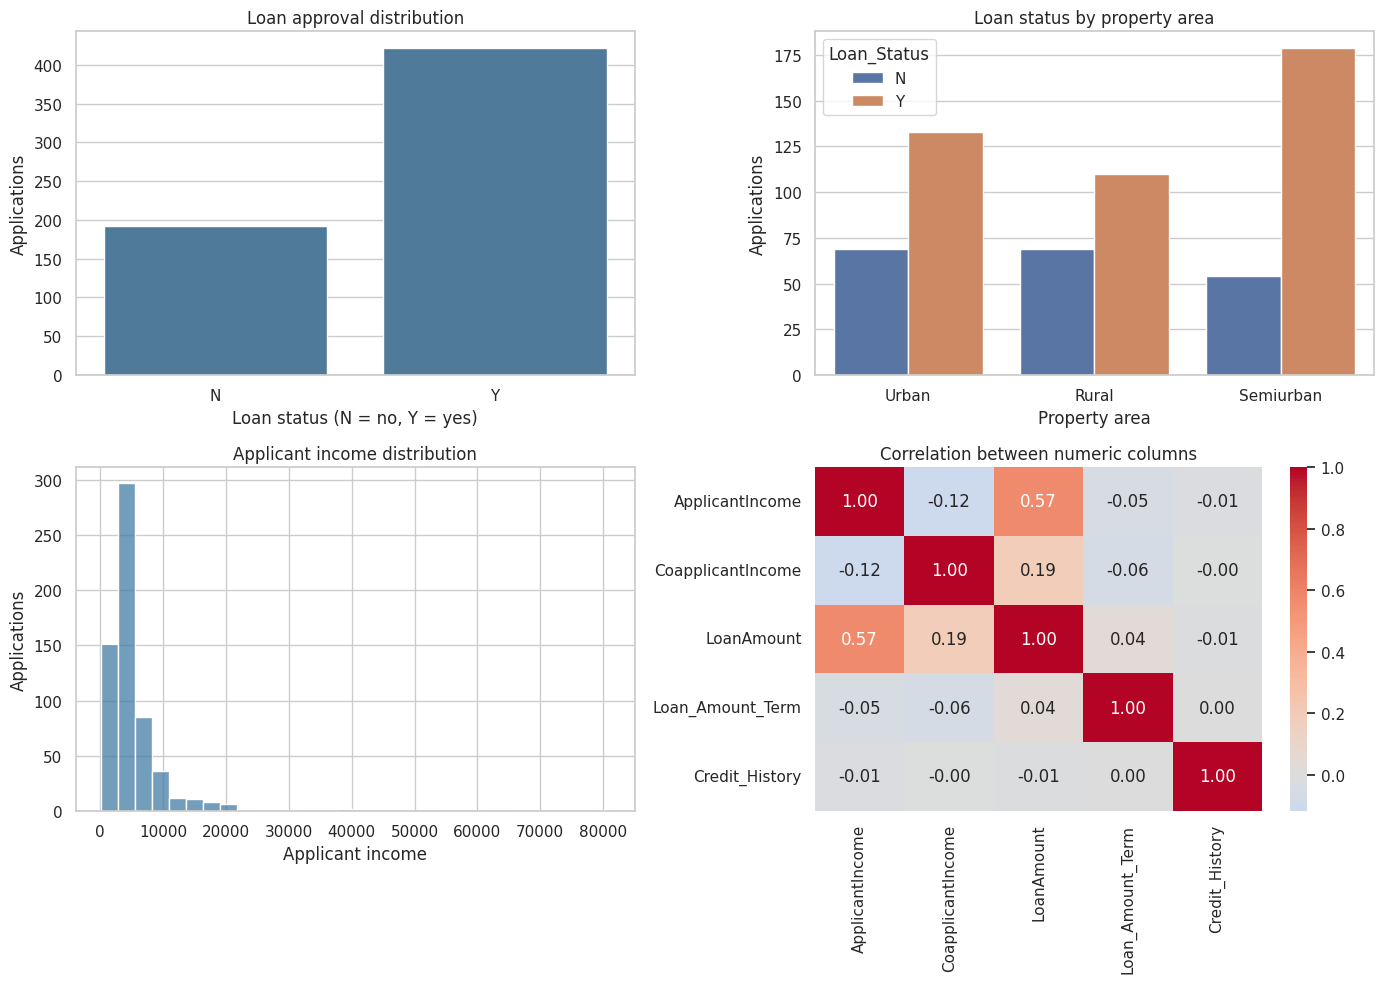

In [2]:
print('Shape (rows, columns):', df.shape)
print('\nColumn information:')
df.info()
print('\nFirst five rows:')
print(df.head().to_string())
print('\nNumeric summary:')
print(df.describe().round(2).to_string())
print('\nCategorical summary:')
print(df.describe(include='object').to_string())
print('\nTarget distribution:')
print(df['Loan_Status'].value_counts(dropna=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=df, x='Loan_Status', order=['N', 'Y'], color='#437CA5', ax=axes[0, 0])
axes[0, 0].set(title='Loan approval distribution', xlabel='Loan status (N = no, Y = yes)', ylabel='Applications')
sns.countplot(data=df, x='Property_Area', hue='Loan_Status', hue_order=['N', 'Y'], ax=axes[0, 1])
axes[0, 1].set(title='Loan status by property area', xlabel='Property area', ylabel='Applications')
sns.histplot(data=df, x='ApplicantIncome', bins=30, color='#437CA5', ax=axes[1, 0])
axes[1, 0].set(title='Applicant income distribution', xlabel='Applicant income', ylabel='Applications')
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('Correlation between numeric columns')
plt.tight_layout()
plt.show()

### EDA observations
The approval counts show whether one target class is more common. The income histogram reveals a long right tail, so a log-income feature may be useful. Property-area counts provide a comparison of approvals and rejections, but areas with more applicants can also have larger bars. Correlation summarizes linear associations; it does not establish causation. I keep valid high-income values rather than removing them only because they are large.

## Step 2 — Clean the data
I remove duplicate rows, show the missing counts, and drop `Loan_ID` because it identifies an application rather than describing it. I trim spaces and treat blank text as missing. `Credit_History` is a category (0 or 1), even though the CSV stores it as a number, so it will use the categorical pipeline.

I keep feature columns with missing entries instead of discarding useful applications. Numeric gaps will use the **training median**, which is less affected by extreme incomes than the mean. Categorical gaps will use the **most frequent training value**. A row with a missing target must be dropped because its correct label is unknown.

The decision table below covers every column with missing values.

Exact duplicate rows: 0
Rows after duplicate removal: 614

Missing values per column before imputation:
Credit_History       50
Self_Employed        32
LoanAmount           22
Dependents           15
Loan_Amount_Term     14
Gender               13
Married               3
Education             0
Loan_ID               0
CoapplicantIncome     0
ApplicantIncome       0
Property_Area         0
Loan_Status           0


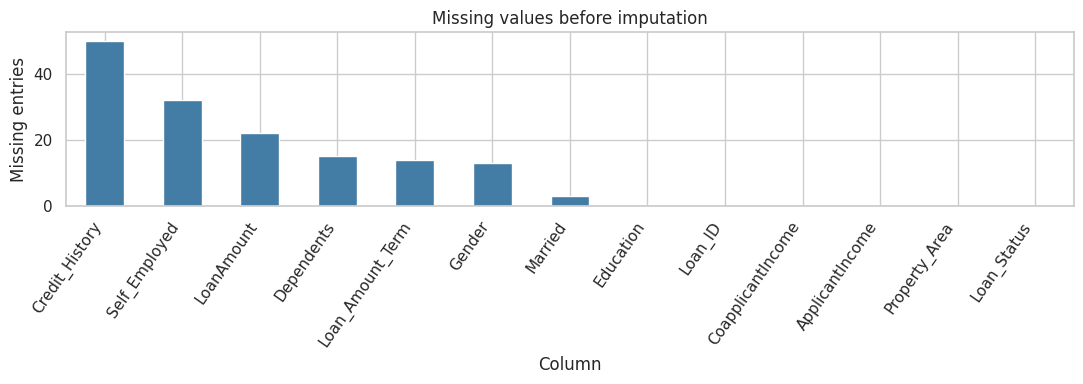


Cleaning decision table:
          Column           Problem                                Action                                                     Reason
  Credit_History 50 missing values   Fill with training mode after split        Keep applications and use a valid, common category.
   Self_Employed 32 missing values   Fill with training mode after split        Keep applications and use a valid, common category.
      LoanAmount 22 missing values Fill with training median after split Keep applications; the median is robust to extreme values.
      Dependents 15 missing values   Fill with training mode after split        Keep applications and use a valid, common category.
Loan_Amount_Term 14 missing values Fill with training median after split Keep applications; the median is robust to extreme values.
          Gender 13 missing values   Fill with training mode after split        Keep applications and use a valid, common category.
         Married  3 missing values   Fill with tra

In [3]:
df = raw_df.copy()
duplicates = int(df.duplicated().sum())
print('Exact duplicate rows:', duplicates)
df = df.drop_duplicates().copy()
print('Rows after duplicate removal:', len(df))

text_columns = df.select_dtypes(include='object').columns
for column in text_columns:
    df[column] = df[column].str.strip().replace('', np.nan)

missing_counts = df.isna().sum().sort_values(ascending=False)
print('\nMissing values per column before imputation:')
print(missing_counts.to_string())
plt.figure(figsize=(11, 4))
missing_counts.plot(kind='bar', color='#437CA5')
plt.title('Missing values before imputation')
plt.xlabel('Column')
plt.ylabel('Missing entries')
plt.xticks(rotation=55, ha='right')
plt.tight_layout()
plt.show()

decisions = []
for column, count in missing_counts.items():
    if count == 0:
        continue
    if column == 'Loan_Status':
        action, reason = 'Drop affected rows', 'A missing target cannot provide a known training label.'
    elif column == 'Loan_ID':
        action, reason = 'Drop entire column', 'An application identifier is not a useful generalizable input.'
    elif column == 'Credit_History' or df[column].dtype == 'object':
        action, reason = 'Fill with training mode after split', 'Keep applications and use a valid, common category.'
    else:
        action, reason = 'Fill with training median after split', 'Keep applications; the median is robust to extreme values.'
    decisions.append([column, f'{count} missing values', action, reason])
if 'Loan_ID' not in [row[0] for row in decisions]:
    decisions.append(['Loan_ID', 'Identifier', 'Drop entire column', 'It identifies an application, not its characteristics.'])
cleaning_decisions = pd.DataFrame(decisions, columns=['Column', 'Problem', 'Action', 'Reason'])
print('\nCleaning decision table:')
print(cleaning_decisions.to_string(index=False))

missing_targets = int(df['Loan_Status'].isna().sum())
df = df.dropna(subset=['Loan_Status']).drop(columns='Loan_ID').copy()
assert df['Loan_Status'].isin(['Y', 'N']).all(), 'Unexpected target label.'
df['Credit_History'] = df['Credit_History'].map({0.0: '0', 1.0: '1'})
print('\nRows dropped for missing targets:', missing_targets)
print('Cleaned shape before feature engineering:', df.shape)
print('Feature gaps remain here on purpose; the training pipelines fill them later.')

## Step 3 — Feature engineering
I add two features using each application's own values. Neither formula learns statistics from other rows or uses the target.

1. **TotalIncome = ApplicantIncome + CoapplicantIncome.** The combined income may describe the household's repayment capacity better than the applicant's income alone. If either component is missing, the total stays missing until training-only median imputation.
2. **LogTotalIncome = log(1 + TotalIncome).** This reduces the influence of very large incomes and can make income differences easier for a model to use. `log1p` also handles zero income.

These are candidate features, not proof of a performance improvement. Their usefulness would be evaluated during later model training.

In [8]:
assert df[['ApplicantIncome', 'CoapplicantIncome']].ge(0).all().all(), 'Income must be nonnegative for these features.'
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['LogTotalIncome'] = np.log1p(df['TotalIncome'])
print(df[['ApplicantIncome', 'CoapplicantIncome', 'TotalIncome', 'LogTotalIncome']].head().round(3).to_string())

   ApplicantIncome  CoapplicantIncome  TotalIncome  LogTotalIncome
0             5849                0.0       5849.0           8.674
1             4583             1508.0       6091.0           8.715
2             3000                0.0       3000.0           8.007
3             2583             2358.0       4941.0           8.506
4             6000                0.0       6000.0           8.700


## Step 4 — Select features and target
I put every input column in `X` and the approval label in `y`. I map `N` to 0 and `Y` to 1 using a fixed definition, so the target is numeric without learning anything from test data. I exclude the target from all input features.

In [7]:
X = df.drop(columns='Loan_Status').copy()
y = df['Loan_Status'].map({'N': 0, 'Y': 1}).astype('int64')
assert 'Loan_Status' not in X.columns
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Target coding: 0 = not approved, 1 = approved')

X shape: (614, 11)
y shape: (614,)
Target coding: 0 = not approved, 1 = approved


## Step 5 — Train/test split
I reserve 20% of applications for testing and use 80% for training. `random_state=42` makes the split reproducible. Because this is classification, `stratify=y` keeps the approval proportions approximately the same in both sets. The raw splits have separate names so that the final `X_train` and `X_test` can refer to the fully processed outputs.

In [9]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training inputs:', X_train_raw.shape, '| training labels:', y_train.shape)
print('Test inputs:    ', X_test_raw.shape, '| test labels:    ', y_test.shape)
class_counts = pd.DataFrame({
    'Full count': y.value_counts(),
    'Train count': y_train.value_counts(),
    'Test count': y_test.value_counts()
}).sort_index()
class_proportions = pd.DataFrame({
    'Full proportion': y.value_counts(normalize=True),
    'Train proportion': y_train.value_counts(normalize=True),
    'Test proportion': y_test.value_counts(normalize=True)
}).sort_index()
class_counts.index.name = class_proportions.index.name = 'Loan_Status (0=N, 1=Y)'
print('\nClass counts:')
print(class_counts.to_string())
print('\nClass proportions:')
print(class_proportions.round(4).to_string())

Training inputs: (491, 11) | training labels: (491,)
Test inputs:     (123, 11) | test labels:     (123,)

Class counts:
                        Full count  Train count  Test count
Loan_Status (0=N, 1=Y)                                     
0                              192          154          38
1                              422          337          85

Class proportions:
                        Full proportion  Train proportion  Test proportion
Loan_Status (0=N, 1=Y)                                                    
0                                0.3127            0.3136           0.3089
1                                0.6873            0.6864           0.6911


## Step 6 — Preprocess using training data only
I combine two pipelines with `ColumnTransformer`:

- **Numbers:** `SimpleImputer(strategy='median')`, then `StandardScaler`. Scaling gives numeric features comparable scales, which can help models that depend on distances or regularization.
- **Categories:** `SimpleImputer(strategy='most_frequent')`, then `OneHotEncoder`. One-hot encoding creates binary columns without assigning an artificial rank. Unknown test categories are safely ignored.

I call `fit_transform` only on training inputs and `transform` on test inputs. The medians, category modes, scaling means and standard deviations, and one-hot category lists therefore come only from training rows. Binary one-hot columns remain 0/1; only numeric columns are standardized.

In [10]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns.tolist()
categorical_columns = X_train_raw.select_dtypes(include='object').columns.tolist()
assert len(numeric_columns) + len(categorical_columns) == X_train_raw.shape[1]
print('Numeric columns:', numeric_columns)
print('Categorical columns:', categorical_columns)

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns)
], remainder='drop')

# This is the only fitting call. Nothing is fitted on the test split.
train_array = preprocessor.fit_transform(X_train_raw)
test_array = preprocessor.transform(X_test_raw)

feature_names = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(train_array, columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(test_array, columns=feature_names, index=X_test_raw.index)
print('\nProcessed training sample:')
print(X_train.head().round(3).to_string())

Numeric columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']

Processed training sample:
     numeric__ApplicantIncome  numeric__CoapplicantIncome  numeric__LoanAmount  numeric__Loan_Amount_Term  categorical__Gender_Female  categorical__Gender_Male  categorical__Married_No  categorical__Married_Yes  categorical__Dependents_0  categorical__Dependents_1  categorical__Dependents_2  categorical__Dependents_3+  categorical__Education_Graduate  categorical__Education_Not Graduate  categorical__Self_Employed_No  categorical__Self_Employed_Yes  categorical__Credit_History_0  categorical__Credit_History_1  categorical__Property_Area_Rural  categorical__Property_Area_Semiurban  categorical__Property_Area_Urban
154                    -0.353                      -0.563               -1.132                      0.281                         0.0    

## Step 7 — Final checks
I check that all four outputs have matching rows, that the two input sets have identical encoded columns, and that neither contains missing or infinite values. I also compare the fitted imputation and scaling statistics to values calculated from training inputs. This provides a check alongside the code showing that only the training split was fitted. The final test data do not need a mean of zero because their values use the training scaler.

In [11]:
print('FINAL OUTPUT SHAPES')
for name, output in [('X_train', X_train), ('X_test', X_test), ('y_train', y_train), ('y_test', y_test)]:
    print(f'{name}: {output.shape}')

print('\nMissing values in X_train:', int(X_train.isna().sum().sum()))
print('Missing values in X_test: ', int(X_test.isna().sum().sum()))
print('Missing values in y_train:', int(y_train.isna().sum()))
print('Missing values in y_test: ', int(y_test.isna().sum()))
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()
assert not y_train.isna().any() and not y_test.isna().any()
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert set(X_train.index).isdisjoint(X_test.index)

fitted_numeric = preprocessor.named_transformers_['numeric']
fitted_categorical = preprocessor.named_transformers_['categorical']
train_medians = X_train_raw[numeric_columns].median()
np.testing.assert_allclose(fitted_numeric.named_steps['imputer'].statistics_, train_medians.to_numpy())
train_numbers_filled = X_train_raw[numeric_columns].fillna(train_medians)
np.testing.assert_allclose(fitted_numeric.named_steps['scaler'].mean_, train_numbers_filled.mean().to_numpy())
np.testing.assert_allclose(fitted_numeric.named_steps['scaler'].var_, train_numbers_filled.var(ddof=0).to_numpy())
assert int(fitted_numeric.named_steps['scaler'].n_samples_seen_) == len(X_train_raw)
for column, mode, categories in zip(
    categorical_columns,
    fitted_categorical.named_steps['imputer'].statistics_,
    fitted_categorical.named_steps['encoder'].categories_
):
    assert mode == X_train_raw[column].mode().iloc[0]
    assert set(categories) == set(X_train_raw[column].fillna(mode).unique())
print('\nAll checks passed.')
print('All learned preprocessing statistics were fitted on training rows only.')
print('X_train, X_test, y_train, and y_test are ready for a machine learning model.')

FINAL OUTPUT SHAPES
X_train: (491, 21)
X_test: (123, 21)
y_train: (491,)
y_test: (123,)

Missing values in X_train: 0
Missing values in X_test:  0
Missing values in y_train: 0
Missing values in y_test:  0

All checks passed.
All learned preprocessing statistics were fitted on training rows only.
X_train, X_test, y_train, and y_test are ready for a machine learning model.


### What I learned
Missing feature values do not always require removing rows. Pipelines keep filling, scaling, and encoding in one repeatable process. A binary numeric-looking field such as credit history may need categorical treatment, and splitting before fitting preprocessing prevents data leakage. The prepared outputs remain available in memory as `X_train`, `X_test`, `y_train`, and `y_test`.